# Lab 4: EDA And Data Viz

This lab will give you a chance to practice and experiment with:
* Working with different file types
* Performing EDA on a variety of types of data
* Producing visualizations to describe distributions and relationships

## Preliminaries

As a few quick reminders:
* You should be able to all of question 1 and most of question 2 by Monday (at least through 2e)
* Make sure your code exactly conforms to specifications (e.g. exactly matching variable names)
* Make sure your code works with any provided test code, and do NOT modify that test code unless explicitly stated
* When answering a specific question, ensure that all your data is within the relevant block.  For text-based answers, you will be asked to edit a specific markdown cell.  For code-based answers, please make sure all code is wholly contained within the relevant  `BEGIN` and `END` comments.
* Please be sure to run the first cell (to import libraries) any time you work on your code.  Please be sure to run all cells, from start to finish, before you submit.  Make sure they run without error, that all provided tests pass, etc.

### A note on imports
If you try to import a package and see a `ModuleNotFoundError`, you may need to install the package.  You usually only have to do this once, and then will have access to that package in future notebooks.  To install a package, add a code cell like the following, where you fill in PACKAGENAME, and run it once.

```
%pip install PACKAGENAME
```

In [103]:
# Optional - uncomment the next line and run this cell if the import for chardet fails
# %pip install chardet

In [104]:
import matplotlib.pyplot as plt
import pandas as pd
import random
import numpy as np 
import seaborn as sns 
import chardet

## Question 1: Loading in Data
In the Lab 4 folders, there are 7 different files begining with `smalldogs`.  All of them store the same data, but in different formats.  Let's start by examining and reading in our familiar CSV file:

In [105]:
dogs1=pd.read_csv('smalldogs.csv')
dogs1.head()

,Breed,Intelligence Percentile,Suitability for Children
0,Border Collie,100.00,Low
1,Golden Retriever,96.55,High
2,German Shorthaired Pointer,93.90,High
3,Basenji,2.29,Medium


And here is a function to look at the start of the file (modified from our Learning Data Science text for this week).

In [106]:
def peek(filepath, n=4):
    '''Prints the first n lines of filepath'''
    with open(filepath) as f:
        for _ in range(n):
            print(f.readline(), end='')
peek("smalldogs.csv")

Breed,Intelligence Percentile,Suitability for Children
Border Collie,100.0,Low
Golden Retriever,96.55,High
German Shorthaired Pointer,93.9,High


The files smalldogs2 through smalldogs6 store the same information but in different formats. In this question, you'll use the file names and the peek method to identify how each file is saved, and then you will figure out the right syntax to read it into pandas.  Here, google may be your best friend (e.g. you could google "how do I read a csv into pandas?") though you are also welcome to ask LLM's to answer that question.  Of course, you may NOT copy these questions into an LLM and ask it to do them for you.  You *are* allowed to ask an LLM how to open a specific file type in pandas, but no more than that.

1a. Read smalldogs2 into pandas as the dataframe `dogs2`

In [107]:
peek("smalldogs2.json", 15)

[
    {
        "Breed":"Border Collie",
        "Intelligence Percentile":100.0,
        "Suitability for Children":"Low"
    },
    {
        "Breed":"Golden Retriever",
        "Intelligence Percentile":96.55,
        "Suitability for Children":"High"
    },
    {
        "Breed":"German Shorthaired Pointer",
        "Intelligence Percentile":93.9,
        "Suitability for Children":"High"


In [108]:
# BEGIN QUESTION 1a
dogs2 = pd.read_json("smalldogs2.json")
# END QUESTION 1a

dogs2.head()

,Breed,Intelligence Percentile,Suitability for Children
0,Border Collie,100.00,Low
1,Golden Retriever,96.55,High
2,German Shorthaired Pointer,93.90,High
3,Basenji,2.29,Medium


1b. Read smalldogs3 into pandas as the dataframe `dogs3`

In [109]:
peek("smalldogs3.tsv", 3)

Breed	Intelligence Percentile	Suitability for Children
Border Collie	100.0	Low
Golden Retriever	96.55	High


In [110]:
# BEGIN QUESTION 1b
dogs3 = pd.read_csv("smalldogs3.tsv", sep = "\t")
# END QUESTION 1b

dogs3.head()

,Breed,Intelligence Percentile,Suitability for Children
0,Border Collie,100.00,Low
1,Golden Retriever,96.55,High
2,German Shorthaired Pointer,93.90,High
3,Basenji,2.29,Medium


1c. Read smalldogs4 into pandas as the dataframe `dogs4`.  This is an excel file, which are a not text files, so we need a different function to peek at what they look like (it's not really useful)

In [111]:
def peek_binary(filepath, n=4):
    '''Prints the first n lines of a binary file, up to width 40'''
    with open(filepath, 'rb') as f:
        for _ in range(n):
            print(f.readline()[:40])

peek_binary("smalldogs4.xlsx", 2)

b'PK\x03\x04\x14\x00\x00\x00\x08\x00\x00\x00?\x00a]I:O\x01\x00\x00\x8f\x04\x00\x00\x13\x00\x00\x00[Content_T'
b'\xb1\xf7Zv\x12J)\x91s)\x85\\\xdb\xf4\x03\x84\xb4\xb6LlIh\xb7i\xfd\xf7\x11\tM\x1d\x08\xa1\x07\x9f\xc4\x8c\xd8\x99\x07\xbb'


In [112]:
# BEGIN QUESTION 1c
dogs4 = pd.read_excel("smalldogs4.xlsx")
# END QUESTION 1c

dogs4.head()

,Breed,Intelligence Percentile,Suitability for Children
0,Border Collie,100.00,Low
1,Golden Retriever,96.55,High
2,German Shorthaired Pointer,93.90,High
3,Basenji,2.29,Medium


1d. Read smalldogs5 into pandas as the dataframe `dog5`

In [113]:
peek("smalldogs5.txt", 5)

Breed:Intelligence Percentile:Suitability for Children
Border Collie:100.0:Low
Golden Retriever:96.55:High
German Shorthaired Pointer:93.9:High
Basenji:2.29:Medium


In [114]:
# BEGIN QUESTION 1d
dogs5 = pd.read_csv("smalldogs5.txt", sep=":")
# END QUESTION 1d

dogs5.head()

,Breed,Intelligence Percentile,Suitability for Children
0,Border Collie,100.00,Low
1,Golden Retriever,96.55,High
2,German Shorthaired Pointer,93.90,High
3,Basenji,2.29,Medium


1e. Read smalldogs6 into pandas as the dataframe `dogs6`. For this one, you should use a `widths` option.  You can count manually, but also use an only character counter (or a code editor the shows the column number of your cursor) to avoid some manual work :).

In [115]:
peek("smalldogs6.txt", 5)

Breed                       Intelligence Percentile  Suitability for Children
Border Collie               100.00                   Low
Golden Retriever            96.55                    High
German Shorthaired Pointer  93.90                    High
Basenji                     2.29                     Medium

In [116]:
# BEGIN QUESTION 1e
dogs6 = pd.read_fwf("smalldogs6.txt", widths=[27, 26, 25])
# END QUESTION 1e

dogs6.head()

,Breed,Intelligence Percentile,Suitability for Children
0,Border Collie,100.00,Low
1,Golden Retriever,96.55,High
2,German Shorthaired Pointer,93.90,High
3,Basenji,2.29,Medium


In [117]:
# Run, but do not edit, this cell
try:
    if (dogs2.loc[0, "Breed"]==dogs3.loc[0, "Breed"]
        ==dogs4.loc[0, "Breed"]==dogs5.loc[0, "Breed"]
        ==dogs6.loc[0, "Breed"]==dogs1.loc[0, "Breed"]):
        print("Public test for 1 passed")
    else:
        print("Public test for 1 FAILED")
except:
    print("Public test for 1 FAILED")

Public test for 1 passed


1f: Briefly identify the file formats in smalldogs5.txt and smalldogs6.txt.

Both are text files, `smalldogs5.txt` separates data by colons, while `smalldogs6.txt` separates data by (nicely formatted) spaces.

Let's try to read in a slightly different CSV

In [118]:
# dogs7=pd.read_csv('smalldogs7.csv')
# dogs7.head()

We might notice something a bit wonky looking in the last row!  Let's use a helpful package chardet that can guess / detect the encoding of a file:

In [119]:
print("Guessing the encoding of the original file:")

with open('smalldogs.csv', 'rb') as f:
    rawdata = f.read()
result = chardet.detect(rawdata)
print(result)

print("Guessing the encoding of smalldogs7:")
with open('smalldogs7.csv', 'rb') as f:
    rawdata = f.read()
result = chardet.detect(rawdata)
print(result)

Guessing the encoding of the original file:
{'encoding': 'ascii', 'confidence': 1.0, 'language': ''}
Guessing the encoding of smalldogs7:
{'encoding': 'ISO-8859-1', 'confidence': 0.73, 'language': ''}


This file appears to be in the ISO-8859-1.  

1g: Figure out what option to add to `pd.read_csv('smalldogs7.csv')` to indicate its encoding.  Then properly load `smalldogs7.csv` in as `dogs7`. 

In [120]:
# BEGIN QUESTION 1g
dogs7=pd.read_csv("smalldogs7.csv", encoding="ISO-8859-1")
dogs7.head()
# END QUESTION 1g

,Breed,Intelligence Percentile,Suitability for Children
0,Border Collie,100.00,Low
1,Golden Retriever,96.55,High
2,German Shorthaired Pointer,93.90,High
3,Löwchen,50.00,Medium


In [121]:
# Run, but do not edit, this cell
try:
    if (dogs7.loc[3, "Breed"]=="Löwchen" and dogs7.loc[2, "Breed"]==dogs3.loc[2, "Breed"]):
        print("Public test for 1g passed")
    else:
        print("Public test for 1g FAILED")
except:
    print("Public test for 1g FAILED")

Public test for 1g passed


## Question 2: EDA with Flu Data

In this question, we'll look at flu data pulled from the [CDC](https://gis.cdc.gov/grasp/fluview/fluportaldashboard.html) in 2026.  The CDC provides some helpful information [here](https://gis.cdc.gov/grasp/fluview/FluViewPhase2QuickReferenceGuide.pdf) and the specific data was curated by the [Data 100 Course Text](https://ds100.org/course-notes/eda/#joining-data-merging-different-dataframe) team and their [github](https://github.com/DS-100).  

Let's start by taking a peak at one of the files, showing that it is mostly a standard CSV file:

In [122]:
peek("ILINet.csv")

PERCENTAGE OF VISITS FOR INFLUENZA-LIKE-ILLNESS REPORTED BY SENTINEL PROVIDERS
REGION TYPE,REGION,YEAR,WEEK,% WEIGHTED ILI,%UNWEIGHTED ILI,AGE 0-4,AGE 25-49,AGE 25-64,AGE 5-24,AGE 50-64,AGE 65,ILITOTAL,NUM. OF PROVIDERS,TOTAL PATIENTS
HHS Regions,Region 1,2015,40,0.743302,0.684364,103,50,,133,23,13,322,134,47051
HHS Regions,Region 2,2015,40,1.03278,1.22475,547,294,,528,123,95,1587,199,129577


In [123]:
ili = pd.read_csv("IlINet.csv")
ili

PERCENTAGE OF VISITS FOR INFLUENZA-LIKE-ILLNESS REPORTED BY SENTINEL PROVIDERS
REGION TYPE REGION    YEAR WEEK % WEIGHTED ILI %UNWEIGHTED ILI AGE 0-4 AGE 25-49 AGE 25-64 AGE 5-24 AGE 50-64 AGE 65 ILITOTAL NUM. OF PROVIDERS                                     TOTAL PATIENTS                            
HHS Regions Region 1  2015 40   0.743302       0.684364        103     50        NaN       133      23        13     322      134                                                            47051                            
            Region 2  2015 40   1.03278        1.22475         547     294       NaN       528      123       95     1587     199                                                           129577                            
            Region 3  2015 40   1.2178         1.24313         401     419       NaN       625      144       81     1670     280                                                           134338                            
            Region 4  2015 40   1.01464        1.15781         486     231       NaN       613      99        75     1504     299                                                           129900                            
...                                                                                                                                                                                            ...                            
            Region 6  2026 3    6.71907        6.40685         1189    1313      NaN       2393     451       375    5721     205                                                            89295                            
            Region 7  2026 3    5.70345        5.79518         518     722       NaN       1174     228       338    2980     164                                                            51422                            
            Region 8  2026 3    3.03915        3.08624         684     670       NaN       1000     246       289    2889     228                                                            93609                            
            Region 9  2026 3    4.85718        4.62364         2045    5863      NaN       4914     2552      3004   18378    402                                                           397479                            
            Region 10 2026 3    5.06699        4.91184         1462    1946      NaN       3526     700       793    8427     332                                                           171565                            

[5381 rows x 1 columns]

2a: Well that looks bad and only has one column, which is not ideal!  Look at the output of `peek` and `ili` above, and (in one sentence) explain why the output is so gnarly.  Looking at the next cell, which adds an option and reads the data much more sensibly, might help.

They treat the table's title as an entry, therefore the table formatting is messed up.

In [124]:
ili = pd.read_csv("IlINet.csv", header=1)
ili

,REGION TYPE,REGION,YEAR,WEEK,% WEIGHTED ILI,%UNWEIGHTED ILI,AGE 0-4,AGE 25-49,AGE 25-64,AGE 5-24,AGE 50-64,AGE 65,ILITOTAL,NUM. OF PROVIDERS,TOTAL PATIENTS
0,HHS Regions,Region 1,2015,40,0.743302,0.684364,103,50,NaN,133,23,13,322,134,47051
1,HHS Regions,Region 2,2015,40,1.032780,1.224750,547,294,NaN,528,123,95,1587,199,129577
2,HHS Regions,Region 3,2015,40,1.217800,1.243130,401,419,NaN,625,144,81,1670,280,134338
3,HHS Regions,Region 4,2015,40,1.014640,1.157810,486,231,NaN,613,99,75,1504,299,129900
4,HHS Regions,Region 5,2015,40,1.042590,1.177230,384,238,NaN,444,159,103,1328,284,112807
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5375,HHS Regions,Region 6,2026,3,6.719070,6.406850,1189,1313,NaN,2393,451,375,5721,205,89295
5376,HHS Regions,Region 7,2026,3,5.703450,5.795180,518,722,NaN,1174,228,338,2980,164,51422
5377,HHS Regions,Region 8,2026,3,3.039150,3.086240,684,670,NaN,1000,246,289,2889,228,93609
5378,HHS Regions,Region 9,2026,3,4.857180,4.623640,2045,5863,NaN,4914,2552,3004,18378,402,397479


We've now read in the data! 

This data comes from about 3200 healthcare providers in the US.  Here are some descriptions of the columns that might help:
* Region breaks the US into 10 HHS regions, which you can find  [here](https://gis.cdc.gov/grasp/fluview/FluViewPhase2QuickReferenceGuide.pdf).  
* The ILITOTAL is the total number of patients presenting ILI symptoms (fever + at least one of cough and sore throat).
* Cases are further refined by age bracket
* TOTAL PATIENTS is the total number of patients seen by those healthcare providers
* The % UNWEIGHTED ILI: This is ILITOTAL/TOTAL PATIENTS.  

2b: What column(s) describe the granularity of this data?

`REGION TYPE`, `REGION`, `YEAR`, `WEEK`

2c: The following code cell indicates that the max `%UNWEIGHTED ILI` is 14.2389. First, identify the week and year with that percentage.  Second, Dane Brammaj says "Wow, in that week over 14\% of people in one region had the flu??" Is Dane correct?  If not, explain the error in his reasoning  

In [125]:
# Run, but do not edit, this cell
ili["%UNWEIGHTED ILI"].max()

14.2389

In [126]:
# Optional code cell to explore 2c
max_ili_row = ili[ili["%UNWEIGHTED ILI"] == ili["%UNWEIGHTED ILI"].max()]
max_ili_row

,REGION TYPE,REGION,YEAR,WEEK,% WEIGHTED ILI,%UNWEIGHTED ILI,AGE 0-4,AGE 25-49,AGE 25-64,AGE 5-24,AGE 50-64,AGE 65,ILITOTAL,NUM. OF PROVIDERS,TOTAL PATIENTS
5321,HHS Regions,Region 2,2025,51,12.7796,14.2389,7759,11040,NaN,19019,3554,3773,45145,389,317053


No, Dane is not correct. The maximum `%UNWEIGHTED ILI` of 14.2389 occurred in Region 2 during week 51 of 2025. However, this percentage represents the proportion of patients seen by the healthcare providers in the CDC's surveillance network who presented ILI symptoms, not the percentage of the general population.

We'd like to plot this data over time, but there isn't a clear datetime column.  Pandas has a lot of flexible options for creating datetime objects.  One convention that is helpful here is the `%Y%W%w` format.  In this format, the first four characters will give the year, the next 1-2 characters will give the week number, and the last charact will give the day of the week (0 for sunday).  For instance
* `2025500` will be parsed as year 2025, week 50, day 0: the sunday of week 50 of the year 2025.
* `202600` will be parsed as year 2026, week 0, day 0: the sunday of the first week of 2026


In [127]:
pd.to_datetime("2025500", format="%Y%W%w")

Timestamp('2025-12-21 00:00:00')

In [128]:
pd.to_datetime("202600", format="%Y%W%w")

Timestamp('2026-01-04 00:00:00')

2d: Add a column `week_start` to the `ili` dataframe that should store a datetime object giving the first day of the week.  To do so,
* Write a function called `add_datetime(df)` that takes in a dataframe `df` (implicitly including columns named `WEEK` and `YEAR`) that uses `.assign` to return a new data frame with column `week_start` containing a datetime object.
* In `add_datetime`, use the `WEEK` and `YEAR` entries to create a string in "%Y%W%w" format and then convert it to a `datetime` object.  For instance, for entry 0 in the data frame (year 2015 and week 40), you would want to use the year and week entries to create the string `2015400` and then convert that to a datetime object (which will encode 2015-10-11).  If you create an intermediate column, be sure to drop it.
* Use `pipe` to apply `add_datetime` to ili

In [129]:
# BEGIN QUESTION 2d
def add_datetime(df):
    return df.assign(
        week_start=pd.to_datetime(
            df['YEAR'].astype(str) + df['WEEK'].astype(str) + '0',
            format='%Y%W%w'
        )
    )

ili = ili.pipe(add_datetime)
# END QUESTION 2d
ili.head()

,REGION TYPE,REGION,YEAR,WEEK,% WEIGHTED ILI,%UNWEIGHTED ILI,AGE 0-4,AGE 25-49,AGE 25-64,AGE 5-24,AGE 50-64,AGE 65,ILITOTAL,NUM. OF PROVIDERS,TOTAL PATIENTS,week_start
0,HHS Regions,Region 1,2015,40,0.743302,0.684364,103,50,NaN,133,23,13,322,134,47051,2015-10-11
1,HHS Regions,Region 2,2015,40,1.032780,1.224750,547,294,NaN,528,123,95,1587,199,129577,2015-10-11
2,HHS Regions,Region 3,2015,40,1.217800,1.243130,401,419,NaN,625,144,81,1670,280,134338,2015-10-11
3,HHS Regions,Region 4,2015,40,1.014640,1.157810,486,231,NaN,613,99,75,1504,299,129900,2015-10-11
4,HHS Regions,Region 5,2015,40,1.042590,1.177230,384,238,NaN,444,159,103,1328,284,112807,2015-10-11


In [130]:
# Run, but do not edit, this cell
try:
    if ili.size==86080 and ili.loc[0, "week_start"].year == 2015  and ili.loc[0, "week_start"].day == 11:
        print("Public test for 2d passed")
    else:
        print("Public test for 2d FAILED")
except:
    print("Public test for 2d FAILED")

Public test for 2d passed


2e: Create a dataframe, `ili_grouped`, that groups by `week_start` and has just two columns: `AGE 5-24` and `ILITOTAL`, respectively giving the totals for those columns that week across all regions.

In [131]:
# BEGIN QUESTION 2e
ili_grouped = ili.groupby('week_start')[['AGE 5-24', 'ILITOTAL']].sum()
# END QUESTION 2e

ili_grouped.head()

,AGE 5-24,ILITOTAL
week_start,,
2015-10-11,3693,10049
2015-10-18,4007,10715
2015-10-25,4360,11584
2015-11-01,4148,11164
2015-11-08,4783,12423


In [132]:
# Run, but do not edit, this cell
try:
    if ili_grouped.size==1072 and ili_grouped.iloc[0, 0]==3693:
        print("Public test for 2e passed")
    else:
        print("Public test for 2e FAILED")
except:
    print("Public test for 2e FAILED")

Public test for 2e passed


2f: Write a single line of code that uses the `lineplot` function from Seaborn to make a line plot where (1) the x-axis is based on `week_start`, and (2) there are two separate lines showing the counts of the `AGE 5-24` and the `ILITOTAL` columns in `ili_grouped.`  Don't worry about adding a title or anything and don't add superfluous options. 

<Axes: xlabel='week_start'>

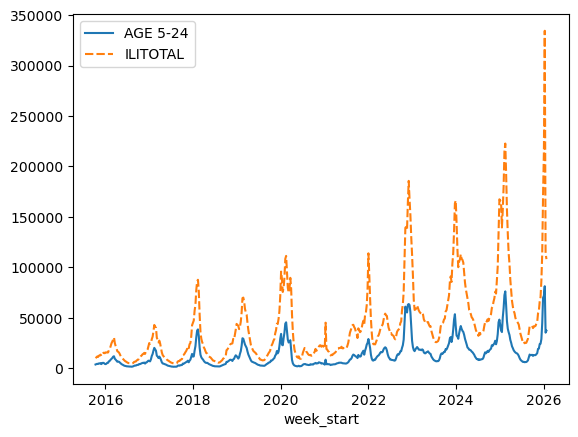

In [133]:
# BEGIN QUESTION 2f
sns.lineplot(data=ili_grouped)
# END QUESTION 2e


2g: Write a single line of code that uses the `scatterplot` function from Seaborn to make a scatterplot plot where (1) there is one point for each entry in `ili_grouped`, (2) the x-axis is based on the total `AGE 5-24` coutns, and (3) the y-axis is based on the total `ILITOTAL` counts.  Don't worry about adding a title or anything and don't add superfluous options. .

<Axes: xlabel='AGE 5-24', ylabel='ILITOTAL'>

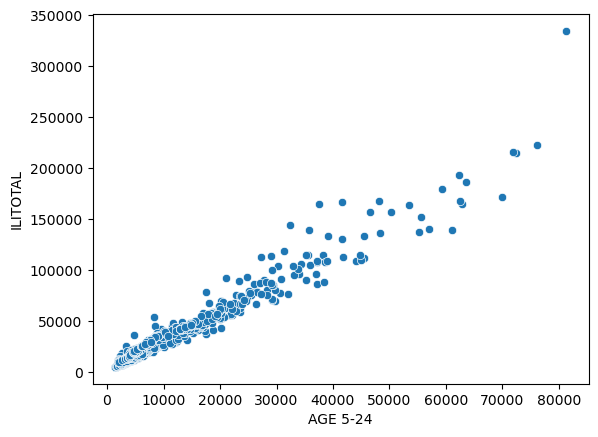

In [134]:
# BEGIN QUESTION 2g
sns.scatterplot(data=ili_grouped, x='AGE 5-24', y='ILITOTAL')
# END QUESTION 2g

## Question 3: Flu Data, Continued

Our lineplot from 2f might suggest that flu cases are generally increasing each year.  Let's investigate that further.

3a: Looking at the scatterplot from 2f, the 2021-22 winter deviates from the trend and seems to have an abnormally low amount of flu cases.  Do some research.  Why might the 2021-22 winter season have had so many fewer ILI cases?

This might be due to COVID lockdown, since that period of time is the most serious of all.

3b: Create a lineplot that shows the percent of all patients who presented ILI symptoms over time (across all regions). For instance, if in week 1 of 2020, there were 1000 total patients across all regions and 100 presented ILI symptoms, you would want 10\%=0.1 plotted for that week.  You may have to do some grouping/adding columns, but your code in 2e-2f will help.

C:\Users\MSI PC\AppData\Local\Temp\ipykernel_7912\2216535732.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ili_pct = ili.groupby('week_start').apply(lambda x: x['ILITOTAL'].sum() / x['TOTAL PATIENTS'].sum()).reset_index()


<Axes: xlabel='week_start', ylabel='percent_ili'>

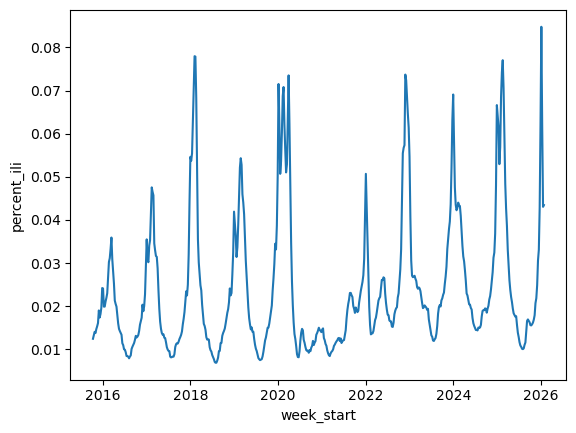

In [135]:
# BEGIN QUESTION 3b
ili_pct = ili.groupby('week_start').apply(lambda x: x['ILITOTAL'].sum() / x['TOTAL PATIENTS'].sum()).reset_index()
ili_pct.columns = ['week_start', 'percent_ili']
sns.lineplot(data=ili_pct, x='week_start', y='percent_ili')
# END QUESTION 3b

3c: The lineplot in 2f showed a market rise in cases over time (spiking during flu season), and suggested that flu cases were generally increasing over time.  However, we don't see that same increase in the overall percent of patients presenting ILI symptoms over time.  Briefly explain how to reconcile these two findings, and idenify any potential lurking variables that might be responsible for the increase we saw in 2f.  Hint: you might want to make a graph of `NUM. OF PROVIDERS` over time!

Text(0, 0.5, 'NUM. OF PROVIDERS')

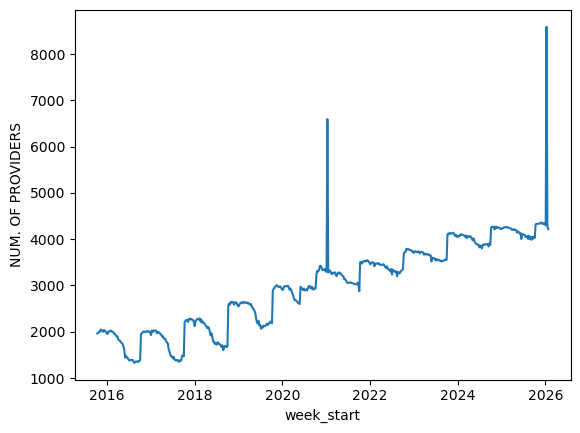

In [136]:
# Optional code cell to help with your investigations in 
ili_providers = ili.groupby('week_start')['NUM. OF PROVIDERS'].sum()
sns.lineplot(data=ili_providers)
plt.xlabel('week_start')
plt.ylabel('NUM. OF PROVIDERS')

We can see an obvious rising trend here, which matches the rising number of cases. However, there are two very suspicious surges in 2021 and 2026, indicating a potential lurking in number of providers.

Let's zoom in on region 3, which includes PA, and try to identify a "reasonable" range for typical `%UNWEIGHTED ILI`. 

3d: Filter down the original `ili` dataframe to `ili3` which should just include data fom Region 3. Then use Seaborn (and one line!) make a histogram of `%UNWEIGHTED ILI` in Region 3.  Don't include a KDE.  Finally, obtain the 5 number summary (min, Q1, median, Q3, max) and identify the month/year with the highest and lowest `%UNWEIGHTED ILI` in Region 3.

count    538.000000
mean       2.227239
std        1.558751
min        0.541546
25%        1.130955
50%        1.718095
75%        2.697195
max        8.641950
Name: %UNWEIGHTED ILI, dtype: float64
Highest %UNWEIGHTED ILI:
week_start         2018-02-11 00:00:00
%UNWEIGHTED ILI                8.64195
Name: 1222, dtype: object
Lowest %UNWEIGHTED ILI:
week_start         2018-08-12 00:00:00
%UNWEIGHTED ILI               0.541546
Name: 1482, dtype: object


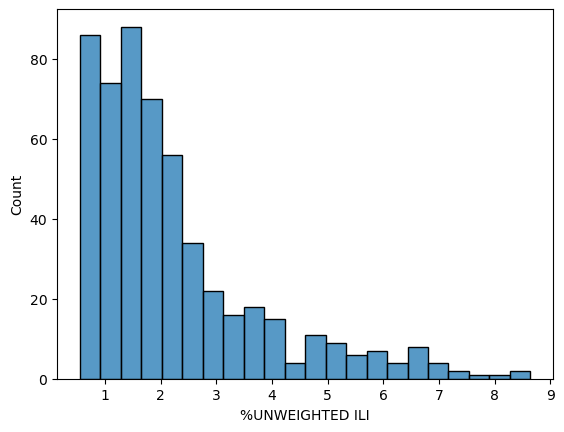

In [137]:
# BEGIN QUESTION 3d
ili3 = ili[ili['REGION'] == 'Region 3']
sns.histplot(data=ili3, x='%UNWEIGHTED ILI', kde=False)
print(ili3['%UNWEIGHTED ILI'].describe())
print("Highest %UNWEIGHTED ILI:")
print(ili3.loc[ili3['%UNWEIGHTED ILI'].idxmax(), ['week_start', '%UNWEIGHTED ILI']])
print("Lowest %UNWEIGHTED ILI:")
print(ili3.loc[ili3['%UNWEIGHTED ILI'].idxmin(), ['week_start', '%UNWEIGHTED ILI']])
# END QUESTION 3d


In [138]:
# Run, but do not edit, this cell
try:
    if ili3.size==8608 and ili3.loc[42, "REGION"]=="Region 3":
        print("Public test for 3d passed")
    else:
        print("Public test for 3d FAILED")
except:
    print("Public test for 3d FAILED")

Public test for 3d passed


This demonstrates strong seasonality in ILI cases, with winter months consistently showing elevated percentages compared to summer and fall months. The upper quartile (2.36%) is more than 5 times higher than the lower quartile (0.91%), indicating substantial seasonal variation in flu activity in Region 3.

One problem with using the above to identify typical weeks is that the data is so seasonal.

3e: Make a histogram of `%UNWEIGHTED ILI` in Region 3, but only including weeks from December to Februrary (peak flu season).  Get the same five number summary for `%UNWEIGHTED ILI` in Region 3 from December to Februrary.  The `.dt.month` attribute of date-time objects will help here.  How does the middle 50% of `%UNWEIGHTED ILI` in Region 3 over all months compare to the same but just during these peak flu months?

count    138.000000
mean       3.564393
std        1.823149
min        0.735565
25%        2.266862
50%        3.189990
75%        4.798620
max        8.641950
Name: %UNWEIGHTED ILI, dtype: float64


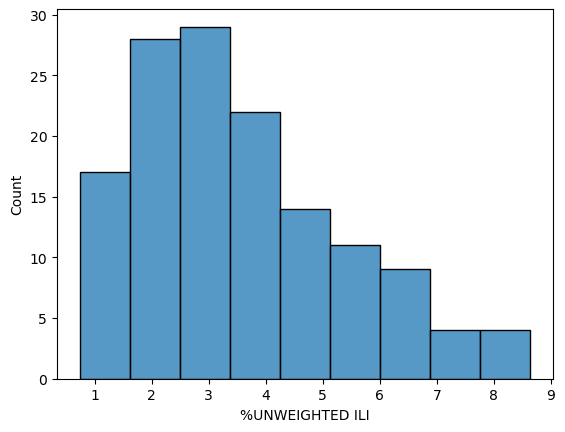

In [139]:
# BEGIN QUESTION 3e
ili3_winter = ili3[ili3['week_start'].dt.month.isin([12, 1, 2])]
sns.histplot(data=ili3_winter, x='%UNWEIGHTED ILI', kde=False)
print(ili3_winter['%UNWEIGHTED ILI'].describe())
# END QUESTION 3e

This shows that during peak flu season, even the lower quartile of ILI cases is higher than the median for the entire year, indicating a strong seasonal pattern with substantially elevated flu activity concentrated in the winter months.

## Question 4: More Dogs

Let's look at some more dog data, curated by [Information is Beautiful](https://informationisbeautiful.net/visualizations/best-in-show-whats-the-top-data-dog/) and originally from the AKC.  Here is some information about these variables:
* Popularity: 1 - 173 (there are more breeds ranked by popularity than in this data set)
* Size: 1=small, 2=medium, 3=large
* Intelligence: 1 - 80, 1 = easiest to train / learn new commands
* Longevity: a weighted average lifepspan
* Suitability for Children: 1 - highly suitable, 2 - medium suitability, 3 - low suitability 

Let's load in the data:

In [140]:
akc=pd.read_csv('AKC2.csv')
akc.head()

,Breed,type,our score,popularity,size,LIFETIME COST,INTELLIGENCE,LONGEVITY,SUITABILITY FOR CHILDREN
0,Border Collie,herding,3.64,45,2,"$20,143",1,12.52,3
1,Border Terrier,terrier,3.61,80,1,"$22,638",30,14.00,1
2,Brittany,sporting,3.54,30,2,"$22,589",19,12.92,2
3,Cairn Terrier,terrier,3.53,59,1,"$21,992",35,13.84,1
4,Welsh Springer Spaniel,sporting,3.34,130,2,"$20,224",31,12.49,1


4a: Let's start by cleaning the data.  Write functions that add columns to a dataframe (using `.assign`):
* `label_size(df)` should take in a dataframe with column `size`, and add a new column `size_cat` containing `small, medium` and `large`
* `label_suit` should take in a dataframe with column `SUITABILITY FOR CHILDREN`, and add a new column `suitability_cat` containing `low, medium` and `high`
* `purpose` should take in a dataframe with column `type` and create a column `play` that is `True` if the dog's type is `toy` or `non-sporting` and `False` otherwise

Then use `pipe` to apply these methods to `akc` and create `akc_clean`.

In [141]:
# BEGIN QUESTION 4a
def label_size(df):
    size_mapping = {1: 'small', 2: 'medium', 3: 'large'}
    return df.assign(size_cat=df['size'].map(size_mapping))

def label_suit(df):
    suit_mapping = {1: 'high', 2: 'medium', 3: 'low'}
    return df.assign(suitability_cat=df['SUITABILITY FOR CHILDREN'].map(suit_mapping))

def purpose(df):
    return df.assign(play=df['type'].isin(['toy', 'non-sporting']))

akc_clean = akc.pipe(label_size).pipe(label_suit).pipe(purpose)

# END QUESTION 4a

akc_clean.head(18)

,Breed,type,our score,popularity,size,LIFETIME COST,INTELLIGENCE,LONGEVITY,SUITABILITY FOR CHILDREN,size_cat,suitability_cat,play
0,Border Collie,herding,3.64,45,2,"$20,143",1,12.52,3,medium,low,False
1,Border Terrier,terrier,3.61,80,1,"$22,638",30,14.00,1,small,high,False
2,Brittany,sporting,3.54,30,2,"$22,589",19,12.92,2,medium,medium,False
3,Cairn Terrier,terrier,3.53,59,1,"$21,992",35,13.84,1,small,high,False
4,Welsh Springer Spaniel,sporting,3.34,130,2,"$20,224",31,12.49,1,medium,high,False
5,English Cocker Spaniel,sporting,3.33,63,2,"$18,993",18,11.66,1,medium,high,False
6,Cocker Spaniel,sporting,3.30,27,1,"$24,330",20,12.50,1,small,high,False
7,Papillon,toy,3.26,38,1,"$21,001",8,13.00,2,small,medium,True
8,Australian Cattle Dog,herding,3.25,60,2,"$20,395",10,11.67,3,medium,low,False
9,Siberian Husky,working,3.22,16,2,"$22,049",45,12.58,1,medium,high,False


In [142]:
# Run, but do not edit, this cell
try:
    if (akc_clean.size == 1044 and akc_clean.loc[13, "size_cat"]=="small"
       and akc_clean.loc[13, "suitability_cat"]=="low"
       and akc_clean.loc[13, "play"]==False):
        print("Public test for 4a passed")
    else:
        print("Public test for 4a FAILED")
except:
    print("Public test for 4a FAILED")
    
akc_clean[["Breed", "size_cat",  "suitability_cat", "play"]][14:25]

Public test for 4a passed


,Breed,size_cat,suitability_cat,play
14,Miniature Schnauzer,small,medium,False
15,Chihuahua,small,low,True
16,Whippet,medium,medium,False
17,Australian Terrier,small,medium,False
18,English Springer Spaniel,medium,high,False
19,West Highland White Terrier,small,high,False
20,Bedlington Terrier,small,medium,False
21,Poodle,medium,medium,True
22,Pointer,large,high,False
23,German Shorthaired Pointer,large,high,False


For the remainder of this question, you will be given a variable or variables.  Use seaborn to make an appropriate plot. Don't worry about titles / axis / font sizes unless specified. Be sure to use the plotting conventions and commands in our code demos - NOT equivalent versions you find online, get from an LLM, etc.  

4b: Make a plot to visualize the distribution of `size_cat`.  Use appropriate coloring and order in increasing size.  

C:\Users\MSI PC\AppData\Local\Temp\ipykernel_7912\49670974.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=akc_clean, x='size_cat', order=['small', 'medium', 'large'], palette='Set2')


<Axes: xlabel='size_cat', ylabel='count'>

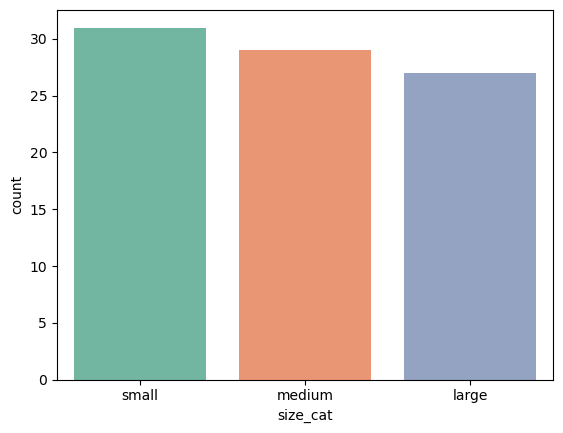

In [143]:
# BEGIN QUESTION 4b
sns.countplot(data=akc_clean, x='size_cat', order=['small', 'medium', 'large'], palette='Set2')
# BEGIN QUESTION 4b

4c: Make a plot to visualize the distribution of `LONGEVITY`.  Use a histogram without KDE.

<Axes: xlabel='LONGEVITY', ylabel='Count'>

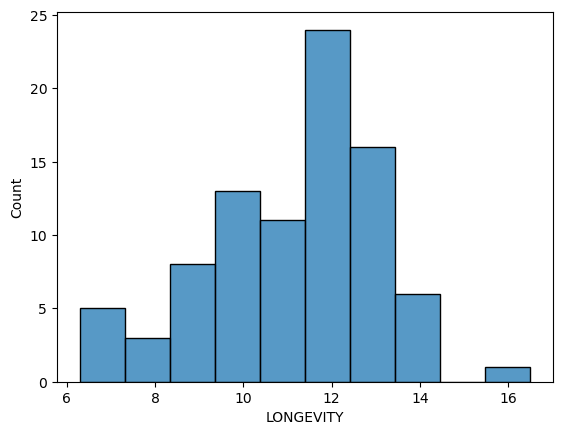

In [144]:
# BEGIN QUESTION 4c
sns.histplot(data=akc_clean, x='LONGEVITY', kde=False)
# BEGIN QUESTION 4c

4d: Make a plot to visualize if intelligence predicts popularity. 

<Axes: xlabel='INTELLIGENCE', ylabel='popularity'>

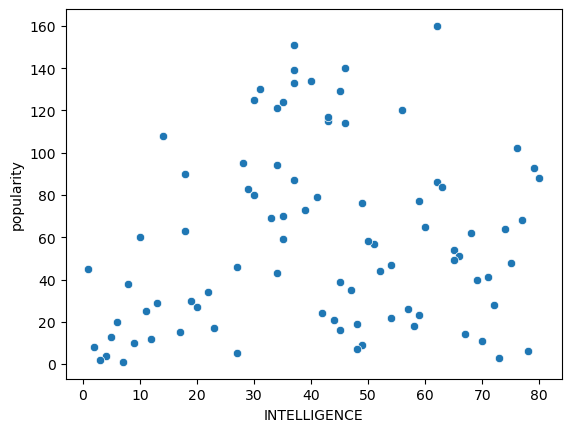

In [145]:
# BEGIN QUESTION 4d
sns.scatterplot(data=akc_clean, x='INTELLIGENCE', y='popularity')
# BEGIN QUESTION 4d

4e: Make a grouped boxplot to visualize the relationship between size and intelligence.  Order by increasing size.  What do you notice?

<Axes: xlabel='size_cat', ylabel='INTELLIGENCE'>

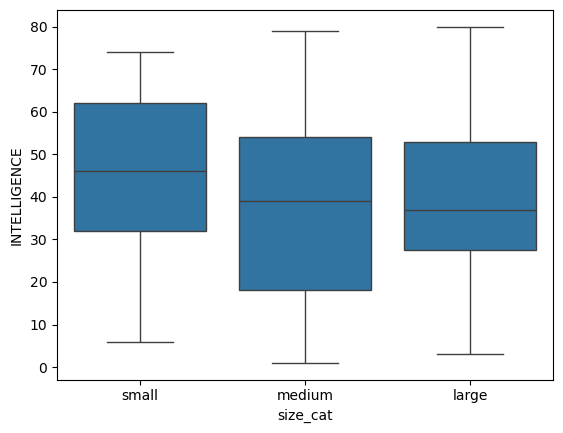

In [146]:
# BEGIN QUESTION 4e
sns.boxplot(data=akc_clean, x='size_cat', y='INTELLIGENCE', order=['small', 'medium', 'large'])
# BEGIN QUESTION 4e

Small cats has a generally higher level of intelligence, but the smartest cats are from other groups.

4f: Make a plot to visualize if longevity predicts higher lifetime costs.  When you do this, you'll probably get a horrible plot because of the way `LIFETIME COST` is formatted.  Thus, you will want to create a new column that converts `LIFETIME COST` to a float.  Think about `strip`ing the leading \$ and `replace` ing any commas (but using `.str` methods), and then converting the cleaned value to a float.

<Axes: xlabel='LONGEVITY', ylabel='lifetime_cost_float'>

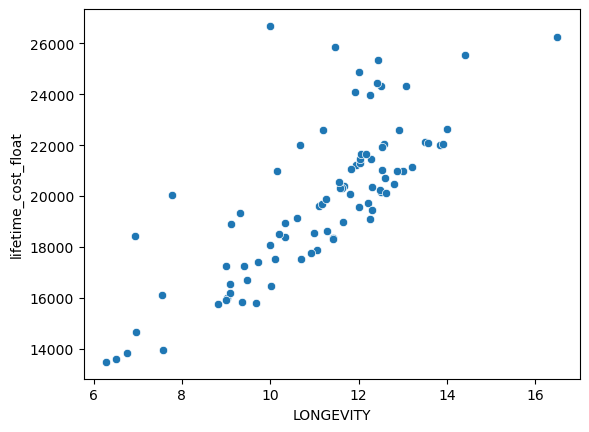

In [147]:
# BEGIN QUESTION 4f
akc_clean_with_cost = akc_clean.assign(
    lifetime_cost_float=akc_clean['LIFETIME COST'].str.replace('$', '').str.replace(',', '').astype(float)
)
sns.scatterplot(data=akc_clean_with_cost, x='LONGEVITY', y='lifetime_cost_float')
# BEGIN QUESTION 4f

## Lab Check Hint for Lab 4

For your next lab check, you should feel good about:
- How to use `.pipe` and `.assign`, as were used several times in this lab.  I may ask you to write a short amount of code using these.
- How to recognize if a file is JSON, tsv, csv, colon separated, fixed width, etc, as in question 1.  I will NOT ask you for the exact pandas syntax to read any of these files - just to be able to recognize which is which from looking at them.
- The results of `.merge` (with various merge options) on small data frames, like in Question 4



# Submission Instructions: due 2/20 at 5pm

We will submit this lab as a PDF.
1. Hit "Kernel --> Restart & Run All"
2. Make sure that all of your cells run and that any output necessary for grading is shown.  Be sure that you pass the provided tests.
3. Create a PDF of your notebook.  To do so, (1) hit File -> Download as -> HTML (or potentially Save and File -> Export Notebook As -> HTML, depending on your version of Jupyter/OS) (2) open that HTML file in Google Chrome (I drag from downloads into a new Chrome tab), and (3) save that HTML file as a PDF (I type `ctrl+P` to print and then select `Save as PDF` as my destination).  Note that this is a bit more involved than just saving as a PDF directly from Jupyter, but usually leads to better-formatted notebooks so **please follow this process exactly.**
4. Skim the PDF and make sure all your code and written responses are fully visible.  If you notice anything (like your code lines are too long and get cut off; your written answers are cut off), fix those issues and repeat the above process. If I cannot see your work, it will not be graded.  It is OK if certain tables are too wide (that's unavoidable) and it's fine if my code/instructions isn't fully visible, but I need to be able to read all of your code/comments/charts.
5. Upload that PDF to Gradescope.  If you run into any issues, please reach out to me before the deadline and document that you've completed everything (e.g. by emailing me a copy of your Jupyter notebook).